# IKpy Quickstart #

Import the IKPy module : 

In [49]:
import ikpy.chain
import numpy as np
import ikpy.utils.plot as plot_utils

The basic element of IKPy is the kinematic `Chain`.
To create a chain from an URDF file : 

In [50]:
# will give warnings, that's OK
my_chain = ikpy.chain.Chain.from_urdf_file("./ur5/ur5_gripper.urdf")

/local/hammits/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link Base link (index: 0) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, link_index))
/local/hammits/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link ee_fixed_joint (index: 7) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, 

# Inverse kinematics

In Inverse Kinematics, you want the "end effector" of your robot to reach a specific 3D position (and in general, orientation) in space. The end effector is the final link of the robot arm, furthest from the base, and possibly a tool that is attached (a gripper in our robot model).

To have a more general representation of position, IKPy works with homogeneous coordinates. Homogenous coordinates are represented as a 4x4 matrix storing both position and orientation. Here we only consider (x,y,z) position, not orientation of the chain.

In [51]:
# define target X, Y, Z coordinate
target_position = [ 1.0872, 0, 0]

In [52]:
# run inverse kinematics solver
print("The joint angles are : ", my_chain.inverse_kinematics(target_position))

The joint angles are :  [ 0.00000000e+00 -1.33227902e-01  8.25717421e-02 -4.96493013e-05
 -2.27617171e+00 -1.36756048e+00  0.00000000e+00  0.00000000e+00]


You can check that the Inverse Kinematics is correct by comparing with the original position vector : 

In [53]:
# run forward kinematics on the inverse kinematics solution to verify
real_frame = my_chain.forward_kinematics(my_chain.inverse_kinematics(target_position))
print("Computed position vector : %s, goal position vector : %s" % (real_frame[:3, 3], target_position))

Computed position vector : [ 9.46755389e-01 -2.38414298e-08  1.15181567e-02], goal position vector : [1.0872, 0, 0]


In [66]:
def sphere(n, radius):
    count = 0;
    points = [];
    while count < n:
        point = np.random.randn(3);
        length = np.linalg.norm(point);
        for x in range(3):
            point[x] = (point[x]/length)*radius;
        count += 1;
        points.append(point);
    return points;

targets = sphere(100, radius=2.0)

reached = []
for target in targets:
    joints = my_chain.inverse_kinematics(target);
    fk = my_chain.forward_kinematics (joints);
    reached.append(fk[:3, 3]);

reached = np.array(reached);
print(reached);

[[-0.49070579 -0.11681046  0.89410435]
 [-0.22623584  0.16070137 -0.81933772]
 [-0.87475261 -0.36650709  0.03573334]
 [-0.47681983 -0.40009744 -0.62843333]
 [ 0.83800687 -0.44615615  0.12176318]
 [-0.4404813  -0.63633567  0.64000109]
 [-0.77816593  0.35919725 -0.3204859 ]
 [ 0.17273141  0.68760888 -0.54308443]
 [ 0.83017113  0.46169905  0.09403137]
 [ 0.59882872 -0.72741666 -0.03184934]
 [ 0.7709735   0.54337807 -0.02359728]
 [ 0.90007157  0.2996009   0.03931603]
 [ 0.39691992  0.74286115 -0.35014242]
 [-0.16616907  0.51732196 -0.6900327 ]
 [ 0.44933548 -0.14437567  0.91355402]
 [-0.36386182 -0.82308896 -0.21498404]
 [-0.10833936  0.90744076 -0.17004691]
 [-0.88168506  0.18064866 -0.21476759]
 [ 0.15362748 -0.62638734 -0.60827296]
 [ 0.83703221  0.30764785  0.41642608]
 [ 0.4365717  -0.77642756 -0.24090048]
 [ 0.24600946  0.54081978 -0.65203408]
 [ 0.04386377 -0.89412268  0.40695526]
 [-0.54226637 -0.74775976 -0.13259848]
 [-0.68243543 -0.33550583  0.5999737 ]
 [ 0.33970628 -0.79460406

# Plotting
And finally plot the result : 

In [68]:
from ikpy.utils import geometry
def get_joints():
    nodes = []
    # "chain" is the Chain object returned by ikpy when it loads URDF file
    # "joints" is the solution from your inverse kinematics solver
    transformation_matrixes = my_chain.forward_kinematics(joints, full_kinematics=True)
    
    # Get the nodes and the orientation from the transformation matrix
    for (index, link) in enumerate(my_chain.links):
        (node, orientation) = geometry.from_transformation_matrix(transformation_matrixes[index])
    
        # Add node corresponding to the link
        nodes.append(node)
    return nodes;

True
True
True
True
True
True
True
True
True


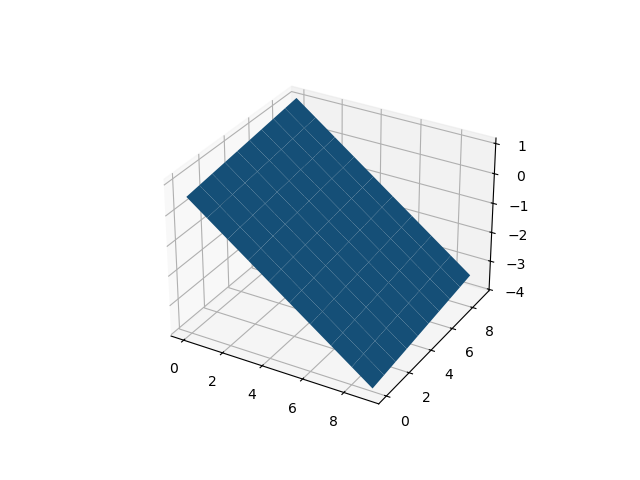

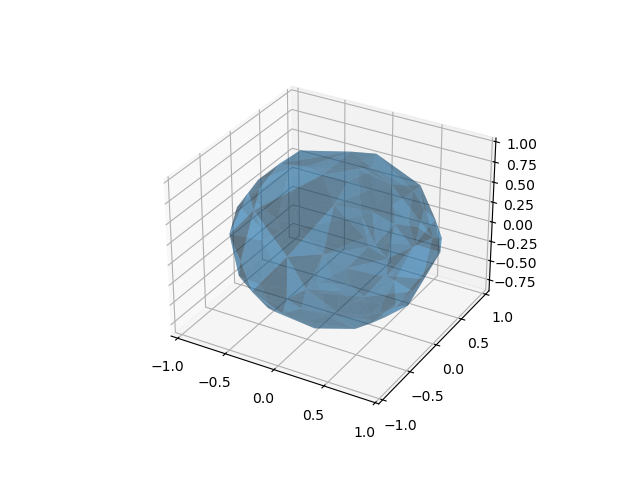

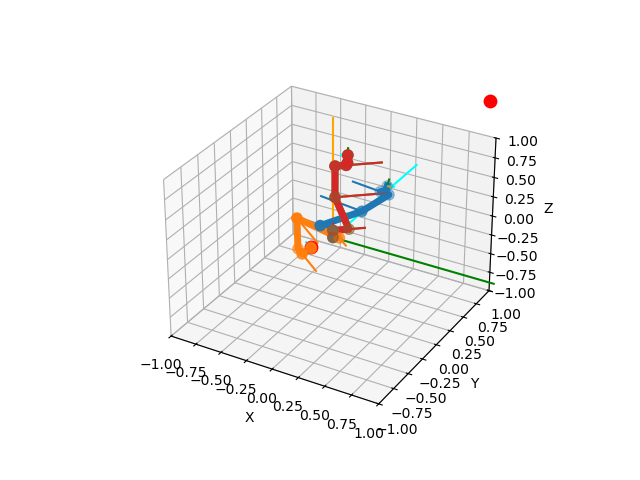

In [73]:
%matplotlib notebook
%matplotlib ipympl

from scipy.spatial import ConvexHull    
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

hull = ConvexHull(reached)
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_trisurf(reached[:,0], reached[:,1], reached[:,2], triangles=hull.simplices, alpha=0.4)
fig, ax = plot_utils.init_3d_figure()

points = [[0.65612, 0.53440, 0.24175],
           [0.62279, 0.51946, 0.25744],
           [0.61216, 0.53959, 0.26394]]

p0, p1, p2 = points
x0, y0, z0 = p0
x1, y1, z1 = p1
x2, y2, z2 = p2

ux, uy, uz = u = [x1-x0, y1-y0, z1-z0]
vx, vy, vz = v = [x2-x0, y2-y0, z2-z0]

u_cross_v = [uy*vz-uz*vy, uz*vx-ux*vz, ux*vy-uy*vx]

point  = np.array(p0)
normal = np.array(u_cross_v)

d = -point.dot(normal)

xx, yy = np.meshgrid(range(10), range(10))

z = (-normal[0] * xx - normal[1] * yy - d) * 1. / normal[2]

target_position = [0,3,0]
my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)

for node in get_joints():
    v = node[:3] - point
    
    dot_product = np.dot(v,normal)
    print(dot_product > 0)

target_position = [-0.1,-0.2,-0.03]
my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)

for node in get_joints():
    v = node[:3] - point
    
    dot_product = np.dot(v,normal)
    print(dot_product > 0)

target_position = [0.7,0.5,8]
my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)

for node in get_joints():
    v = node[:3]- point
    
    dot_product = np.dot(v,normal)
    print(dot_product > 0)

# plot the surface
plt3d = plt.figure().add_subplot(projection="3d")
plt3d.plot_surface(xx, yy, z)
plt.show()

my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)
